# Detecting epidemic changes in functional data

The Python twin of the fdachange R package, whose vignette
(`vignette("fdachange")` in R) this notebook mirrors. The R package is the
reference implementation; the two are held equal by a cross-language parity
test suite, so everything below reproduces the same numbers the R code
produces on the same inputs.

In [1]:
import os
import tempfile

import numpy as np
import matplotlib.pyplot as plt

import fdachange as fc

print("fdachange", fc.__version__)

# Colorblind-safe categorical palette (validated adjacent-pair order);
# assignments are fixed per entity across every figure in this notebook.
pal = {"blue": "#2a78d6", "orange": "#eb6834",
       "aqua": "#1baf7a", "yellow": "#eda100"}
col_changed = pal["blue"]     # curves / cells inside the change window
col_plain = "0.75"            # unchanged curves, recessive marks
proj_col = {"l2": pal["blue"], "ito": pal["orange"],
            "c_max_var": pal["aqua"], "pc1": pal["yellow"]}

plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 96,
                     "axes.spines.top": False, "axes.spines.right": False})


def shade_window(ax, lo, hi):
    """Shade the true change window (annotation, not data)."""
    ax.axvspan(lo, hi, color="0.5", alpha=0.18, zorder=0)

fdachange 0.2.0


## The epidemic alternative

An *epidemic* (changed-segment) alternative means a sample
$X_1, \dots, X_n$ is i.i.d. except on an unknown window
$I^\ast = \{k^\ast + 1, \dots, k^\ast + l^\ast\}$, where the
distribution changes and then changes back. fdachange implements four
weighted scan tests for this alternative:

| Test | Function | Sensitive to |
|---|---|---|
| Wilcoxon-type antisymmetric-kernel scan | `wilcoxon_statistic` | location (`h_w`) or scale/tail (`h_0`) changes |
| Lp empirical-process scan | `lp_statistic` | general distributional change |
| RKHS kernel mean-embedding scan | `rkhs_statistic` | general distributional change |
| Birbilas CUSUM-type functional statistic | `far1_statistic` | functional mean jumps under FAR(1) dependence |

Each scan weights a window of relative length $t$ by the Hoelder-type
weight $w(t) = t^{-\gamma} \log(c/t)^{-\beta}$: larger $\gamma$
up-weights short windows, at the price of heavier-tailed null
distributions.

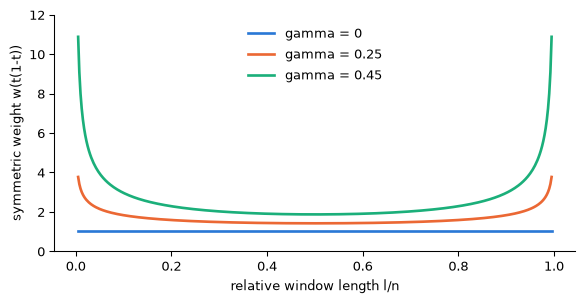

In [2]:
t = np.linspace(0.005, 0.995, 400)
fig, ax = plt.subplots(figsize=(7, 3.2))
for g, c in zip([0, 0.25, 0.45], pal.values()):
    ax.plot(t, fc.holder_weight(t * (1 - t), g), lw=2, color=c,
            label=f"gamma = {g}")
ax.set(xlabel="relative window length l/n",
       ylabel="symmetric weight w(t(1-t))", ylim=(0, 12))
ax.legend(frameon=False)
plt.show()

## Quick start: a scalar series

`generate_s1` draws an i.i.d. N(0, 1) series with an epidemic mean shift
on a chosen window; `epidemic_test` runs a calibrated test and localizes
the change. `rng=` takes a numpy `Generator`, a seed, or `None`.

In [3]:
x = fc.generate_s1(200, a=1, ec_interval=(0.4, 0.7), rng=1)
ht = fc.epidemic_test(x, "wilcoxon", gamma=0.25)
print(ht)

	Epidemic change scan test (Wilcoxon-type antisymmetric kernel)

T = 4.0292, gamma = 0.25, p-value = 0
alternative hypothesis: an epidemic (changed then restored) segment
critical value (alpha = 0.05): 2.5379  [30000 null draws]
detected window: observations 81..140 (fractions 0.400..0.700)


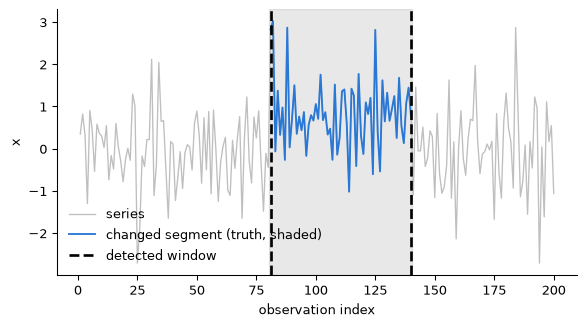

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(np.arange(1, 201), x, color=col_plain, lw=1, label="series")
shade_window(ax, 80.5, 140.5)                # true window I* = {81..140}
ax.plot(np.arange(81, 141), x[80:140], color=col_changed, lw=1.4,
        label="changed segment (truth, shaded)")
ax.axvline(ht.k + 1, ls="--", lw=2, color="black", label="detected window")
ax.axvline(ht.m, ls="--", lw=2, color="black")
ax.set(xlabel="observation index", ylabel="x")
ax.legend(frameon=False, loc="lower left")
plt.show()

The shaded band is the true window; the dashed lines are the window the
scan reports (`ht.k + 1` to `ht.m`, the thesis convention
$I(k, m) = \{k+1, \dots, m\}$).

## Functional data and the benchmark scenarios

The functional scenarios return a matrix with one curve per column,
sampled on `l + 1` grid points (`skfda.FDataGrid` inputs are accepted
everywhere a matrix is). `generate_f1` puts centred-Pareto coefficients
on a cosine basis inside the window; `generate_f5` adds a spike to
i.i.d. Wiener (random-walk) curves.

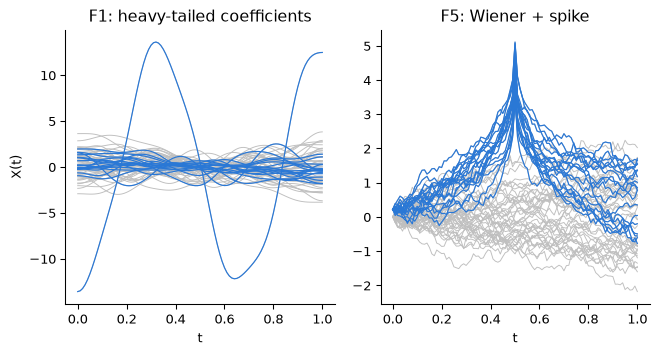

In [5]:
n = 60
X1 = fc.generate_f1(n, a=3, rng=2)
X5 = fc.generate_f5(n, a=4, rng=2)
s = np.linspace(0, 1, X5.shape[0])
win = slice(24, 42)                          # curves 25..42: the exact window at n = 60

fig, axes = plt.subplots(1, 2, figsize=(7, 3.8))
for ax, X, title in zip(axes, [X1, X5],
                        ["F1: heavy-tailed coefficients", "F5: Wiener + spike"]):
    ax.plot(s, X, color=col_plain, lw=0.7)
    ax.plot(s, X[:, win], color=col_changed, lw=0.9)
    ax.set(xlabel="t", title=title)
axes[0].set_ylabel("X(t)")
fig.tight_layout()
plt.show()

Blue curves are the ones inside the change window. F5's spike is the
dissertation's spike function
$f_\alpha(t) = (1 - |t - 1/2|^\alpha)^{1/\alpha}$, a
Hoelder-$\alpha$ cusp at $t = 1/2$ (default `spike_alpha = 0.45`):

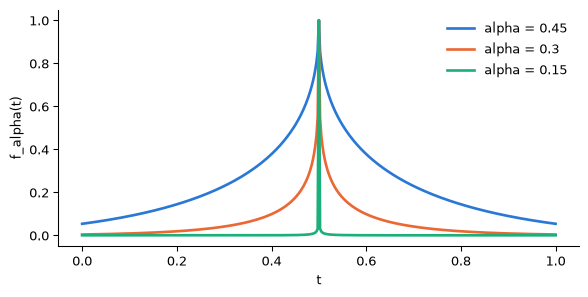

In [6]:
def f_alpha(t, al):
    return (1 - np.abs(t - 0.5) ** al) ** (1 / al)


tt = np.linspace(0, 1, 401)
fig, ax = plt.subplots(figsize=(7, 3.2))
for al, c in zip([0.45, 0.3, 0.15], pal.values()):
    ax.plot(tt, f_alpha(tt, al), lw=2, color=c, label=f"alpha = {al}")
ax.set(xlabel="t", ylabel="f_alpha(t)")
ax.legend(frameon=False)
plt.show()

## Projections visualized

The scalar scans consume a numeric series, so functional data is first
reduced by a projection. Different projections preserve different aspects
of the change; the color of each projection is fixed throughout this
notebook. `project_l2` (the $L_2$ norm of each curve) is deterministic;
`project_ito` (integral against one shared random Wiener path per call),
`project_c_max_var` (evaluate every curve at a randomly chosen critical
point of the variance function) and `project_pc1` (inner product with the
leading functional principal component) mirror the R implementations in
pure numpy.

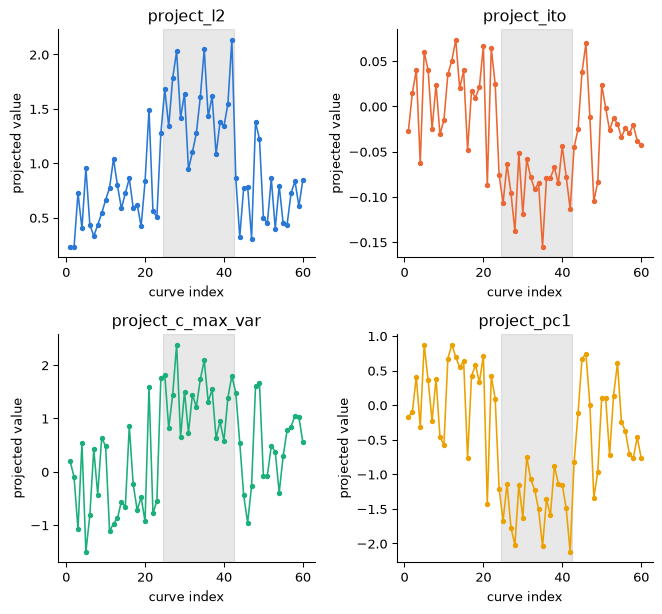

In [7]:
projs = {"l2": fc.project_l2(X5), "ito": fc.project_ito(X5, rng=3),
         "c_max_var": fc.project_c_max_var(X5, rng=4),
         "pc1": fc.project_pc1(X5)}
fig, axes = plt.subplots(2, 2, figsize=(7, 6.5))
for ax, (nm, p) in zip(axes.flat, projs.items()):
    ax.plot(np.arange(1, n + 1), p, "o-", ms=3, lw=1.2, color=proj_col[nm])
    shade_window(ax, 24.5, 42.5)
    ax.set(title=f"project_{nm}", xlabel="curve index",
           ylabel="projected value")
fig.tight_layout()
plt.show()

At this spike amplitude several projections separate the window: the
point-evaluation `c_max_var` because the variance-critical point lands on
the spike, and the norm `l2` because a bump of height 4 moves the whole
curve's norm. The projection whose random direction can simply miss the
spike (`ito`) shows the weakest separation - and the full power study
below confirms that ordering, with the point-evaluation advantage
concentrated at *faint* amplitudes where the norm barely moves. The
stochastic projections (`ito`, `c_max_var`, `wiener`) draw a fresh random
direction on every call; `scan_over_splits` exploits exactly that to
aggregate independent chunks.

## Testing, localization, calibration

Every method runs through the same `epidemic_test` interface. On the
projected F5 series (a larger sample this time so the asymptotic
calibration is comfortable):

In [8]:
Xb = fc.generate_f5(200, a=3, rng=5)
xb = fc.project_l2(Xb)
print(f"{'method':<10}{'statistic':>10}{'critical':>10}{'p-value':>10}  window")
for m in ["wilcoxon", "lp", "rkhs"]:
    ht = fc.epidemic_test(xb, m, gamma=0.25)
    print(f"{m:<10}{ht.statistic:>10.3f}{ht.critical_value:>10.3f}"
          f"{ht.p_value:>10.3g}  [{ht.k + 1}, {ht.m}]")

method     statistic  critical   p-value  window
wilcoxon       5.349     2.538         0  [80, 140]
lp             1.560     0.683         0  [80, 140]
rkhs           1.686     1.142         0  [80, 140]


Calibration is resolved automatically, in this order:

1. **Shipped Monte-Carlo caches** for the published (gamma, kernel, p)
   cells: `wilcoxon_null_draws`, `lp_null_draws`, `rkhs_null_draws`,
   `far1_null_draws` - converted from the same frozen sources as the R
   package's, so critical values are bit-identical (at gamma = 0 the
   Wilcoxon cell's 95% point sits just below the exact Brownian-bridge
   range value 1.7473).
2. **Your own draws** for anything else - simulate, then either pass via
   `epidemic_test(null=)` or store for automatic lookup
   (`FDACHANGE_CACHE_DIR` relocates the cache; a demo-sized run below).

In [9]:
print("cv at gamma = 0 from the shipped cell:", round(fc.wilcoxon_critical_value(0), 4))

# store into a throwaway cache dir: this run is demo-sized only
os.environ["FDACHANGE_CACHE_DIR"] = tempfile.mkdtemp(prefix="fdachange-")
draws = fc.simulate_wilcoxon_null(200, gamma=0.1, grid=500, rng=8)
fc.save_null_draws(draws, "wilcoxon", gamma=0.1)
print("cv from your draws:", round(fc.wilcoxon_critical_value(0.1), 4))

cv at gamma = 0 from the shipped cell: 1.7346


cv from your draws: 2.0317


One caveat worth repeating from the R reference pages: the Wilcoxon scan
and the ecdf-path Lp scan are rank-based, so their nulls apply to any
continuous data. The RKHS caches are tied to the H0 distribution named by
their `baseline` tag - for other marginals, simulate with
`simulate_rkhs_null(rdist=...)`.

## A small power simulation

A miniature version of the spike experiment: does the projection choice
matter for detecting a faint spike? (Small `n` and `n_rep` keep this cell
fast.)

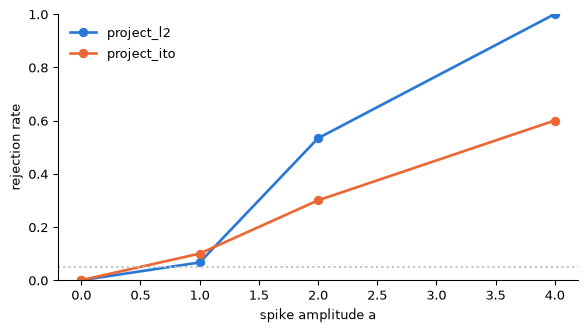

In [10]:
rng = np.random.default_rng(42)
a_grid = [0, 1, 2, 4]
n_rep = 30
cv = fc.wilcoxon_critical_value(0.25)
power = {}
for nm in ["l2", "ito"]:
    proj = fc.projection_fn(nm)
    power[nm] = [
        np.mean([fc.wilcoxon_statistic(
            proj(fc.generate_f5(100, a=a, rng=rng), rng=rng),
            0.25, kernel="h_0") > cv for _ in range(n_rep)])
        for a in a_grid]

fig, ax = plt.subplots(figsize=(7, 3.6))
for nm, pw in power.items():
    ax.plot(a_grid, pw, "o-", lw=2, color=proj_col[nm],
            label=f"project_{nm}")
ax.axhline(0.05, color=col_plain, ls=":")
ax.set(xlabel="spike amplitude a", ylabel="rejection rate", ylim=(0, 1))
ax.legend(frameon=False)
plt.show()

The committed full-scale study in the repository
(`reproduction/data/f5_spike_power.csv`: n = 400, N_rep = 100, corrected
Wilcoxon and Lp scans over c_max_var / l2 / ito) gives the complete
picture, and its verdict is nuanced: the point-evaluation projection
`c_max_var` is the most powerful for *faint* spikes (for the Lp scan at
a = 0.5 - 1 it reaches 2 - 3 times the power of `l2`) and has the best
mean power overall for Lp, but it is not uniformly dominant - at large
amplitudes the norm projections catch up, and for the Wilcoxon h_0 scan
`l2` wins on average.

## An application: the shipped telco_far1 dataset

`load_telco_far1` returns the R package's `telco_far1` dataset
(bit-identical values): daily voice-usage curves for 11 simulated
customer clusters, 50 months x 28 days each, following a functional
autoregressive FAR(1) process with $\beta(t) = 0.7\sqrt{t}$. Clusters
`cl2`-`cl4` contain a designed epidemic change ($\sqrt{t}$-shaped
jumps); `cl5`-`cl11` violate the null in other ways (trends, level
shifts, outliers); `cl1` is a clean null. Each cluster carries its design
as attributes (`change_months`, `jump`, `multiplier`, `outliers`,
`outlier_months`).

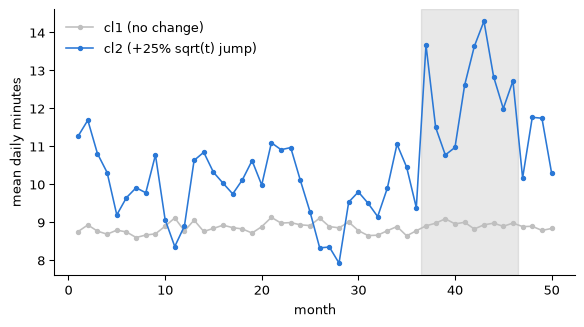

In [11]:
telco = fc.load_telco_far1()
cl1, cl2 = telco["cl1"], telco["cl2"]
months = np.arange(1, 51)

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(months, cl1.y.mean(axis=1), "o-", ms=3, lw=1.2, color=col_plain,
        label="cl1 (no change)")
ax.plot(months, cl2.y.mean(axis=1), "o-", ms=3, lw=1.2, color=col_changed,
        label="cl2 (+25% sqrt(t) jump)")
shade_window(ax, cl2.change_months[0] - 0.5, cl2.change_months[-1] + 0.5)
ax.set(xlabel="month", ylabel="mean daily minutes")
ax.legend(frameon=False)
plt.show()

One month is one curve (28 days), so the test scans 50 curves per
cluster; transpose `y` to the package's `(grid, n)` layout, project,
test, localize:

In [12]:
for nm in ["cl1", "cl2", "cl3", "cl4"]:
    c = telco[nm]
    ht = fc.epidemic_test(fc.project_l2(c.y.T), "lp", gamma=0.25)
    designed = (f"{c.change_months[0]}..{c.change_months[-1]}"
                if c.change_months.size else "none")
    detected = f"[{ht.k + 1}, {ht.m}]" if ht.reject else "-"
    print(f"{nm:<5} T = {ht.statistic:6.3f}  cv = {ht.critical_value:.3f}  "
          f"reject = {str(ht.reject):<5}  detected {detected:<10} "
          f"designed {designed}")

cl1   T =  0.670  cv = 0.683  reject = False  detected -          designed none
cl2   T =  0.948  cv = 0.683  reject = True   detected [37, 49]   designed 37..46
cl3   T =  0.764  cv = 0.683  reject = True   detected [38, 48]   designed 37..49
cl4   T =  0.956  cv = 0.683  reject = True   detected [22, 37]   designed 37..50


The Lp scan keeps the clean cluster quiet and localizes `cl2` and `cl3`
on the designed windows. `cl4` rejects, but its detected window is not
meaningful: the designed jump deepens through the *end* of the sample, so
the change never reverts and the alternative is one-sided rather than
epidemic - the scan only recovers the start boundary. Two caveats, stated
honestly: months are serially dependent (FAR(1)), while the shipped null
caches assume independent observations, so the size of these tests on
this data is only approximate - for exact calibration simulate the null
from the same FAR(1) model and pass it via `epidemic_test(null=)`. And at
50 curves per cluster the windows are short: the Wilcoxon scan on the
same projections also rejects `cl2` and `cl4` but localizes the long
complementary segment instead.

The dissertation's own application scans weekly electricity
balancing-price curves and first reconstructs them on the level-$K$
Faber-Schauder (order-2 B-spline) space. `reconstruct` exposes that
preprocessing step; here on the spike function sampled with noise:

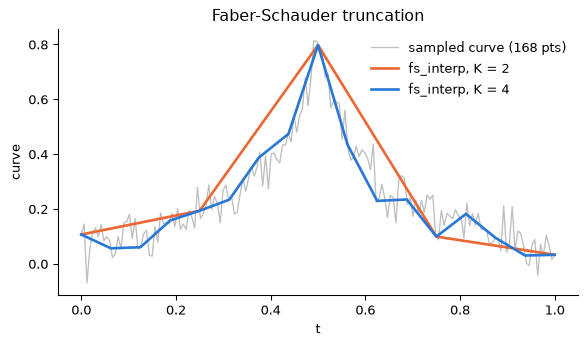

In [13]:
t_in = np.linspace(0, 1, 168)
y = f_alpha(t_in, 0.45) + np.random.default_rng(6).normal(0, 0.05, 168)
Y = y[:, None]
r2 = fc.reconstruct(Y, "fs_interp", K=2)
r4 = fc.reconstruct(Y, "fs_interp", K=4)

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(t_in, y, color=col_plain, lw=1, label="sampled curve (168 pts)")
ax.plot(r2["argvals"], r2["X"][:, 0], color=pal["orange"], lw=2,
        label="fs_interp, K = 2")
ax.plot(r4["argvals"], r4["X"][:, 0], color=pal["blue"], lw=2,
        label="fs_interp, K = 4")
ax.set(xlabel="t", ylabel="curve", title="Faber-Schauder truncation")
ax.legend(frameon=False)
plt.show()

(`fs_ls` performs least squares onto the same polygonal space, and
`bspline_pen` adds a roughness penalty via scikit-fda - the `[fda]`
extra.)

## Citing

Cite the dissertation and articles listed by `citation("fdachange")` in
the R package: Bartkus (2026) <doi:10.15388/vu.thesis.950>, Bartkus and
Rackauskas (2025) <doi:10.1007/s10986-025-09699-7> and (2026)
<doi:10.15388/namc.2026.31.44489>, and Birbilas (2025)
<doi:10.15388/vu.thesis.841> for the FAR(1) statistic.